# Inferring Human Activity States with a Hidden Markov Model

**Rehabilitation adherence monitoring after knee or hip replacement**

HonourGod Kilechukwu Levison &nbsp;|&nbsp; Machine Learning Techniques II &nbsp;|&nbsp; Formative 2

---

After joint replacement surgery the patient goes home with a prescription that is
entirely about movement: walk a prescribed amount each day, build standing tolerance
gradually, avoid high-impact loading until the joint has healed. The surgeon observes
none of it, and follow-up depends on patient recall weeks later. A smartphone already
in the patient's pocket carries the sensors needed to measure that prescription
directly.

Each of the four states maps onto a clinical question:

| State | Clinical meaning |
|---|---|
| **Walking** | the prescribed mobilisation dose |
| **Standing** | weight-bearing tolerance |
| **Jumping** | contraindicated high-impact loading - should raise an alert |
| **Still** | phone on a surface, i.e. **not being carried at all** |

The last state is what makes the problem harder than it first looks. A system that cannot separate
*the patient is resting* from *the phone is on the kitchen table* will record a
non-wear period as clinical inactivity and report that the patient is not recovering.

The activity itself is never measured - only a noisy, orientation-dependent stream of
accelerations is. The true state is **hidden** behind that stream, activities persist
for many seconds, and they change in patterned rather than arbitrary ways. That is
exactly the structure a Hidden Markov Model encodes.

---

This notebook runs the complete pipeline and generates every figure used in the
report. All analysis code lives in `../src/` as importable modules; the notebook
orchestrates them so that each step stays readable.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import viz
from config import (ACTIVITIES, BOUNDARY_GUARD_S, CLIP_SECONDS, HOP_SAMPLES,
                    HOP_SECONDS, N_COMPONENTS, PROCESSED, RANDOM_SEED,
                    REQUESTED_HZ, TARGET_HZ, TRANSITION_SMOOTHING,
                    WINDOW_SAMPLES, WINDOW_SECONDS)
from data import load_circuits, load_clean, load_unseen
from features import build_feature_table, feature_columns, prune_features
from hmm import GaussianHMM, align_states, remap
from metrics import confusion, format_report, overall, per_state_report
from pipeline import Preprocessor, split_recordings, subset, to_sequences
from transitions import as_frame, dwell_summary, estimate_A, estimate_pi

pd.set_option("display.width", 180, "display.max_columns", 40)
np.set_printoptions(precision=4, suppress=True)

print(f"states              {ACTIVITIES}")
print(f"requested rate      {REQUESTED_HZ:g} Hz")
print(f"analysis rate       {TARGET_HZ:g} Hz")
print(f"clip length         {CLIP_SECONDS:g} s")
print(f"window              {WINDOW_SECONDS:g} s = {WINDOW_SAMPLES} samples, "
      f"hop {HOP_SECONDS:g} s = {HOP_SAMPLES} samples")

states              ['Still', 'Standing', 'Walking', 'Jumping']
requested rate      50 Hz
analysis rate       50 Hz
clip length         8 s
window              2 s = 100 samples, hop 1 s = 50 samples


---
## 1. Data collection and pre-processing

### 1.1 Collection protocol

All recordings were made with **Sensor Logger v1.68** on a single **Xiaomi 2312DRA50G**
(Android, platform version 36), logging the **accelerometer** and **gyroscope**.

| | |
|---|---|
| Requested sampling rate | **50 Hz** (`sampleRateMs = 20`) for *both* sensors |
| Achieved sampling rate | **51.33 Hz** mean (range 51.327 - 51.341 Hz) |
| Max inter-sample gap | 0.019 s - no dropouts in any file |
| Training session | 52 files, 13 per activity, 2026-10-30, phone in hand at waist level |
| Unseen session | 12 files, 3 per activity, different room, **phone in trouser pocket** |
| Circuits | 2 continuous recordings (~94 s) containing real activity transitions |

Phone placement was held constant within a session, with one deliberate exception:
**Still** means the phone rests on a flat surface, because that state represents
*non-wear* rather than a posture.

### 1.2 Harmonising the sampling rate

Three separate problems had to be resolved before any analysis, and all three are
handled in `data.py`:

1. **The requested rate is not the delivered rate.** 50 Hz was requested; the device
   delivered ~51.33 Hz with jitter.
2. **The two sensors are written on separate clocks.** Sensor Logger writes
   `Accelerometer.csv` and `Gyroscope.csv` as independent files with their own
   nanosecond timestamps; the rows are *not* mutually aligned, so they cannot simply
   be concatenated column-wise.
3. **Annotations use a different clock again.** The circuit `Annotation.csv` timestamps
   come from a monotonic boot clock (~7.96 days) while the sensor files use Unix epoch,
   so only the *intervals* between annotation taps are meaningful.

The resolution is to **linearly interpolate both sensor streams onto one shared
uniform grid at exactly 50 Hz**. This makes every file an identical length in samples,
guarantees that accelerometer and gyroscope values at a given index refer to the same
instant, and means a window is the same duration everywhere. Had a second phone with
a different native rate been used, the same step would have resampled it to the same
grid - the procedure generalises without modification.

### 1.3 Trimming

Raw recordings ran 9.3 - 12.0 s. The **central 8.0 s** of each is retained, which keeps
every file inside the required 5 - 10 s band and gives 13 x 8 = **104 s per activity**
against a 90 s floor. The trim is not arbitrary: the measured standard deviation of the
first and last ~1.5 s is **1.3 - 1.8x** that of the middle on Standing and Walking,
because the hand is moving to and from the screen. Those seconds are contamination,
not signal.

### 1.4 Choosing the window length from the sampling rate

The window is **2.0 s with a 1.0 s hop (50% overlap)**. Every part of that follows from
the 50 Hz rate and the physics of the activities:

- **2.0 s x 50 Hz = exactly 100 samples.** An integer sample count means every window
  has identical FFT bin positions, so a spectral feature means the same thing in
  every window. A window length that did not divide evenly would make the frequency
  features incomparable between windows.
- **Frequency resolution = 1 / 2.0 s = 0.5 Hz.** Walking cadence is ~1 Hz and jumping
  ~3.6 Hz in this data, so 0.5 Hz resolution separates them comfortably.
- **2 s spans 3 - 4 walking gait cycles**, enough for a repeating pattern to be visible
  rather than a fragment of one stride.
- **Nyquist = 25 Hz**, far above the ~0.5 - 5 Hz band where human activity energy lives,
  so no aliasing.
- **2 s fits inside even the shortest permitted 5 s file**, so no recording is wasted;
  an 8 s clip yields 7 windows.
- **50% overlap** roughly doubles the window count (364 rather than ~190) and ensures
  no event falls entirely on a window boundary.

The cost is temporal resolution: a 2 s window cannot localise a transition better than
about +/- 1 s, which is visible as lag at the boundaries of the decoded circuit plots
in section 4.

In [2]:
clean = load_clean()
unseen = load_unseen()
circuit_samples, segments = load_circuits()

manifest = pd.read_csv(PROCESSED / "manifest.csv")
summary = manifest.groupby("activity").agg(
    files=("recording", "count"),
    total_clean_s=("clean_duration_s", "sum"),
    raw_min_s=("raw_duration_s", "min"),
    raw_max_s=("raw_duration_s", "max"),
    native_hz=("native_acc_hz", "mean"),
    resampled_hz=("resampled_hz", "first"),
    samples_per_file=("n_samples", "first"),
)
print("TRAINING SESSION")
print(summary.round(3).to_string())
print(f"\ntotal files {len(manifest)}   "
      f"every cleaned file: {CLIP_SECONDS:g} s at {TARGET_HZ:g} Hz = "
      f"{manifest.n_samples.unique()[0]} samples")
print(f"\nUNSEEN SESSION   {unseen.recording.nunique()} files, "
      f"{unseen.groupby('activity').recording.nunique().to_dict()}")
print(f"CIRCUITS         {circuit_samples.recording.nunique()} recordings, "
      f"{len(segments)} annotated segments")

TRAINING SESSION
          files  total_clean_s  raw_min_s  raw_max_s  native_hz  resampled_hz  samples_per_file
activity                                                                                       
Jumping      13          104.0     10.399     11.467     51.337          50.0               400
Standing     13          104.0     10.077     12.087     51.327          50.0               400
Still        13          104.0     10.532     11.801     51.330          50.0               400
Walking      13          104.0      9.388     11.853     51.337          50.0               400

total files 52   every cleaned file: 8 s at 50 Hz = 400 samples

UNSEEN SESSION   12 files, {'Jumping': 3, 'Standing': 3, 'Still': 3, 'Walking': 3}
CIRCUITS         2 recordings, 14 annotated segments


In [3]:
# Class separability on the single strongest raw descriptor, before any modelling.
sep = (clean.groupby("activity")
       .apply(lambda g: pd.Series({
           "acc_mag_std": g.groupby("recording").acc_mag.std().mean(),
           "gyr_mag_std": g.groupby("recording").gyr_mag.std().mean()}),
              include_groups=False)
       .loc[ACTIVITIES])
sep["x_quieter_than_next"] = (sep.acc_mag_std.shift(-1) / sep.acc_mag_std).round(1)
print("Mean within-clip standard deviation by activity (training session)\n")
print(sep.round(4).to_string())

Mean within-clip standard deviation by activity (training session)

          acc_mag_std  gyr_mag_std  x_quieter_than_next
activity                                               
Still          0.0031       0.0002                 14.3
Standing       0.0443       0.0121                 28.3
Walking        1.2518       0.8094                  7.6
Jumping        9.4965       1.0885                  NaN


### 1.5 Sample data visualisations

The three figures below are generated directly from the cleaned data by `viz.py`
and are the sample-data plots used in the report.

C:\Users\levis\OneDrive\Documents\ALU_Projects\ALU_Formatives\hmm-human-activity-recognition\results\figures\01_sample_signals.png


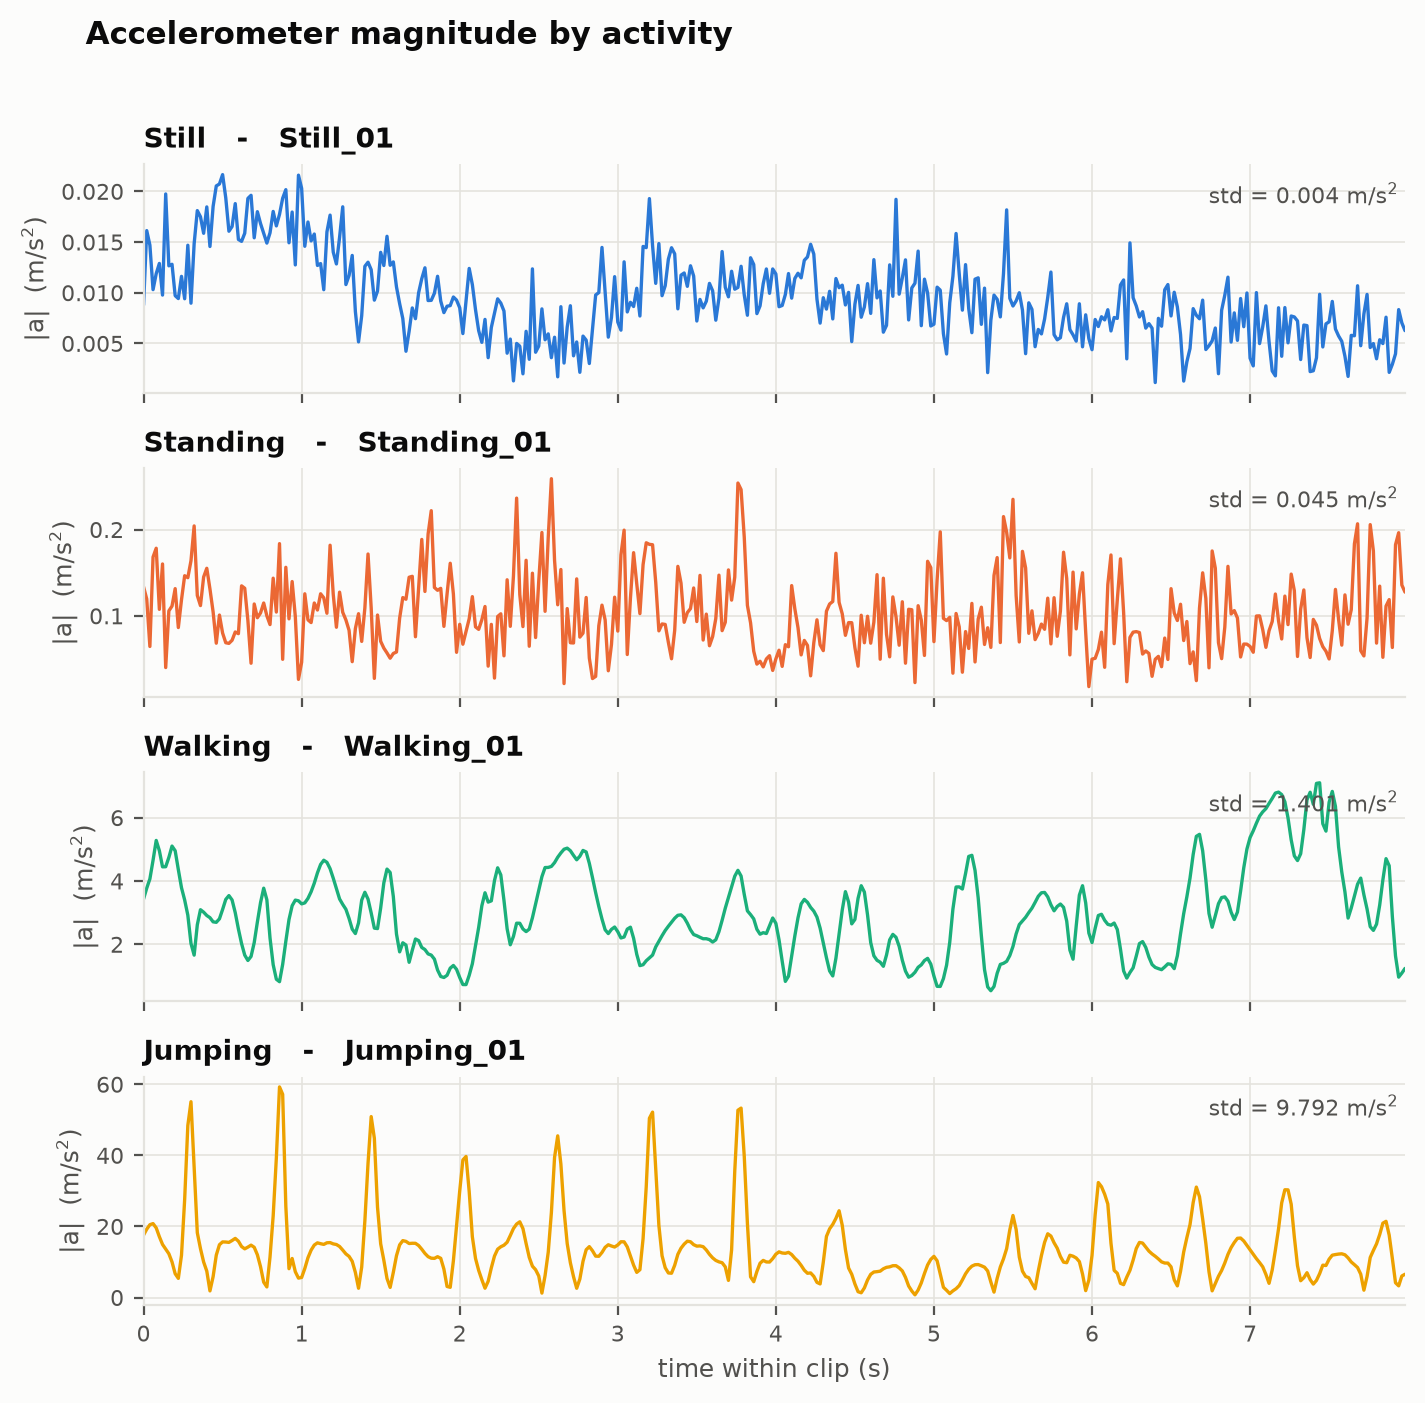

In [4]:
print(viz.plot_sample_signals(clean))
from IPython.display import Image, display
display(Image(filename=str(viz.FIGURES / "01_sample_signals.png")))

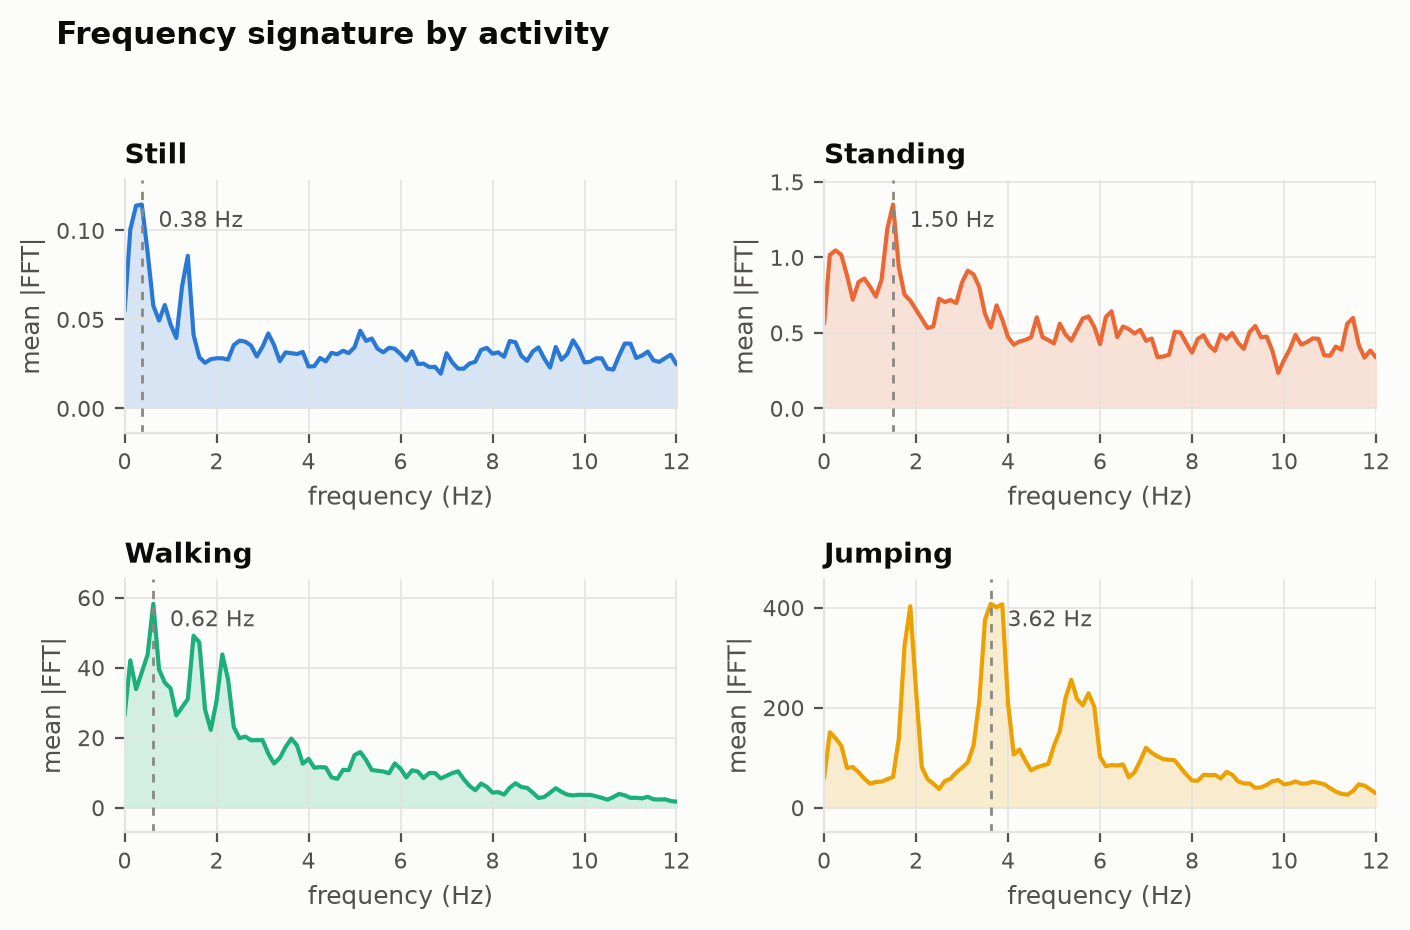

In [5]:
viz.plot_spectra(clean)
display(Image(filename=str(viz.FIGURES / "02_spectra.png")))

---
## 2. Feature extraction

### 2.1 What is extracted and why

A window of 100 raw samples across 8 channels is 800 numbers - far too many, and
mostly redundant. Each window is reduced to descriptors that capture *how* the signal
moves rather than its moment-by-moment value.

Eight channels are described: the six raw axes (`acc_x/y/z`, `gyr_x/y/z`) plus two
derived magnitude channels `acc_mag` and `gyr_mag`, the Euclidean norms. The magnitudes
matter because they are **invariant to how the phone is rotated** - a phone held at a
different angle produces different per-axis values but the same magnitude.

**Time-domain features** (14 per channel) describe amplitude and shape:

| Feature | Why it distinguishes these activities |
|---|---|
| **variance / std / RMS** | the single most discriminative family here - the four activities span three orders of magnitude in movement energy (Still 0.003, Standing 0.048, Walking 1.26, Jumping 9.59 m/s^2) |
| **range, min, max** | jumping produces extreme peaks on landing that a mean would hide |
| **MAD, IQR, median** | robust versions of the above, unaffected by a single landing spike |
| **mean absolute jerk** | rate of change of acceleration; walking and jumping involve abrupt direction reversals, standing does not |
| **zero-crossing rate** | counts oscillations about the mean - periodic gait crosses often, a static posture drifts |
| **skewness / kurtosis** | jumping is heavily peaked (long still phases punctuated by impacts), walking is near-symmetric |
| **signal magnitude area (SMA)** | total absolute acceleration across all three axes - a standard overall intensity measure in activity recognition |
| **cross-axis correlation** | walking couples vertical and forward axes through the gait cycle; a stationary phone does not |

**Frequency-domain features** (9 per channel), from the Hann-windowed real FFT of the
mean-removed signal:

| Feature | Why it distinguishes these activities |
|---|---|
| **dominant frequency** | the clearest physical separator: walking ~1 Hz cadence, jumping ~3.6 Hz, static postures have no periodic component |
| **magnitude at dominant frequency** | how strongly periodic the motion is, not just where the peak sits |
| **spectral energy** | total power - separates motion from rest independent of waveform shape |
| **spectral entropy** | low for the regular periodicity of walking and jumping, high for the broadband sensor noise of Still |
| **spectral centroid** | the spectrum's centre of mass; shifts upward with impact-heavy motion |
| **band energy ratios** (0.5-1.5, 1.5-3, 3-10, 10-25 Hz) | the bands are chosen around the measured activity frequencies: postural sway, walking cadence and its stride harmonic, jumping and landing impact, and sensor noise up to Nyquist |

Bands start at 0.5 Hz rather than 0 deliberately. The signal is mean-removed before the
FFT so the DC bin is excluded by construction; at 0.5 Hz resolution a 0 - 0.5 Hz band
would contain no bins at all and be identically zero in every window. (It was, in the
first extraction - the band edges were corrected after inspection.)

That yields **192 features per window**.

In [6]:
train = build_feature_table(clean)
unseen_tbl = build_feature_table(unseen)
cols = feature_columns(train)

print(f"{len(train)} training windows x {len(cols)} features")
print(train.groupby("activity").agg(windows=("window_index", "count"),
                                    recordings=("recording", "nunique")).to_string())
print(f"\n{len(unseen_tbl)} unseen windows")
assert train[cols].isna().sum().sum() == 0, "NaNs in feature table"
print("\nno NaNs - every statistic undefined on a constant signal is guarded,")
print("which matters because Still sits at the sensor noise floor.")

364 training windows x 192 features
          windows  recordings
activity                     
Jumping        91          13
Standing       91          13
Still          91          13
Walking        91          13

84 unseen windows

no NaNs - every statistic undefined on a constant signal is guarded,
which matters because Still sits at the sensor noise floor.


In [7]:
# Evidence for the feature justifications above: Fisher ratio = between-class
# variance / within-class variance. Higher means the feature separates the four
# activities more cleanly.
X = train[cols].to_numpy(float)
y = train.state.to_numpy()
gm = X.mean(0)
between = np.zeros(len(cols)); within = np.zeros(len(cols))
for k in range(len(ACTIVITIES)):
    Xk = X[y == k]
    between += len(Xk) * (Xk.mean(0) - gm) ** 2
    within += ((Xk - Xk.mean(0)) ** 2).sum(0)
fisher = pd.Series(between / np.maximum(within, 1e-12), index=cols)

print("15 most discriminative features\n")
print(fisher.nlargest(15).round(2).to_string())
print("\nby family:")
fam = pd.Series({
    "time-domain amplitude (std/var/rms/mean)":
        fisher[[c for c in cols if c.endswith(("_std", "_var", "_rms", "_mean"))]].mean(),
    "jerk": fisher[[c for c in cols if c.endswith("_jerk")]].mean(),
    "SMA": fisher[["acc_sma", "gyr_sma"]].mean(),
    "frequency-domain": fisher[[c for c in cols if any(
        t in c for t in ("dom_hz", "energy", "entropy", "centroid", "band_"))]].mean(),
    "cross-axis correlation": fisher[[c for c in cols if c.startswith("corr_")]].mean(),
})
print(fam.round(2).to_string())

15 most discriminative features

acc_mag_mean      50.15
acc_mag_median    46.52
acc_mag_rms       39.76
acc_z_jerk        27.78
acc_z_std         27.28
acc_z_rms         27.17
acc_mag_jerk      25.76
acc_sma           25.01
gyr_mag_jerk      24.83
acc_z_min         24.26
acc_z_mad         23.83
acc_z_range       23.43
acc_mag_mad       23.07
gyr_x_jerk        21.42
acc_mag_std       19.36

by family:
time-domain amplitude (std/var/rms/mean)     9.33
jerk                                        17.94
SMA                                         18.40
frequency-domain                             3.16
cross-axis correlation                       1.81


### 2.2 Normalisation: why Z-score

The 192 features are on wildly different scales - a variance in (m/s^2)^2 is numerically
thousands of times larger than a correlation coefficient bounded in [-1, 1], and a
spectral energy larger again. Three consequences force normalisation:

1. **PCA is variance-maximising**, so without rescaling the components would be chosen
   almost entirely by whichever features happen to carry the largest raw numbers,
   regardless of how informative they are.
2. **The HMM emissions are diagonal-covariance Gaussians.** A feature with a huge
   variance would dominate the log-likelihood sum and effectively silence the others.
3. Features are **not bounded** and contain genuine extreme values (landing impacts),
   so min-max scaling would be driven by single outliers and compress the rest of each
   distribution into a narrow band.

**Z-score standardisation** (subtract the mean, divide by the standard deviation,
`sklearn.preprocessing.StandardScaler`) is the right choice because it puts every
feature on a common scale of "standard deviations from its own mean", preserves the
*shape* of each distribution including informative outliers, and is the natural
companion to Gaussian emissions - a standardised feature is exactly what a zero-mean,
unit-variance Gaussian expects. It is also linear and invertible, so nothing is lost.

**Fitted on the training split only.** The scaler's mean and standard deviation, the
pruning decision and the PCA basis are all estimated from training windows and then
applied unchanged to the unseen session. Fitting on everything would leak held-out
information into the model and inflate the result.

### 2.3 Dimensionality reduction

Pruning constant and near-duplicate features (|r| > 0.95 - std, variance and RMS of a
zero-mean channel measure almost the same thing) leaves ~121. That is still far too
many emission parameters for 364 windows, so PCA follows.

The component count is **not** chosen by variance share. After pruning, 90% of variance
needs 27 components - but variance in a mixed time/frequency space is not the same as
class-discriminative information, and 27 diagonal-covariance dimensions would mean 216
emission parameters fitted from 364 observations. Instead **D is the smallest dimension
reaching the accuracy plateau** of a diagonal-covariance Gaussian classifier (the HMM's
own emission model) under 5-fold cross-validation grouped **by recording**:

| D | 2 | 3 | **4** | 6 | 12 | 16 |
|---|---|---|---|---|---|---|
| accuracy | 0.939 | 0.997 | **1.000** | 1.000 | 1.000 | 0.974 |

D = 16 already degrades through covariance overfitting. **D = 4** is used throughout:
8 emission parameters per state.

In [8]:
pre = Preprocessor(n_components=N_COMPONENTS).fit(train, verbose=True)
Z_train = pre.transform(train)
Z_unseen = pre.transform(unseen_tbl)

ev = pre.pca_.explained_variance_ratio_
print(f"\nretained {len(pre.columns_)} of {len(cols)} features after pruning")
print(f"PCA -> {N_COMPONENTS} components, {ev.sum():.1%} of variance")
print("per component:", ", ".join(f"PC{i+1} {v:.1%}" for i, v in enumerate(ev)))
print(f"\nstandardised feature means ~0: {np.abs(pre.scaler_.transform(train[pre.columns_]).mean(0)).max():.2e}")

pruned 192 -> 121 features (0 constant, 71 redundant at |r| > 0.95)
PCA 121 -> 4 dims, 67.9% of variance (41.2%, 18.5%, 4.8%, 3.4%)

retained 121 of 192 features after pruning
PCA -> 4 components, 67.9% of variance
per component: PC1 41.2%, PC2 18.5%, PC3 4.8%, PC4 3.4%



standardised feature means ~0: 6.25e-16


C:\Users\levis\OneDrive\Documents\ALU_Projects\ALU_Formatives\time_series_forecasting\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


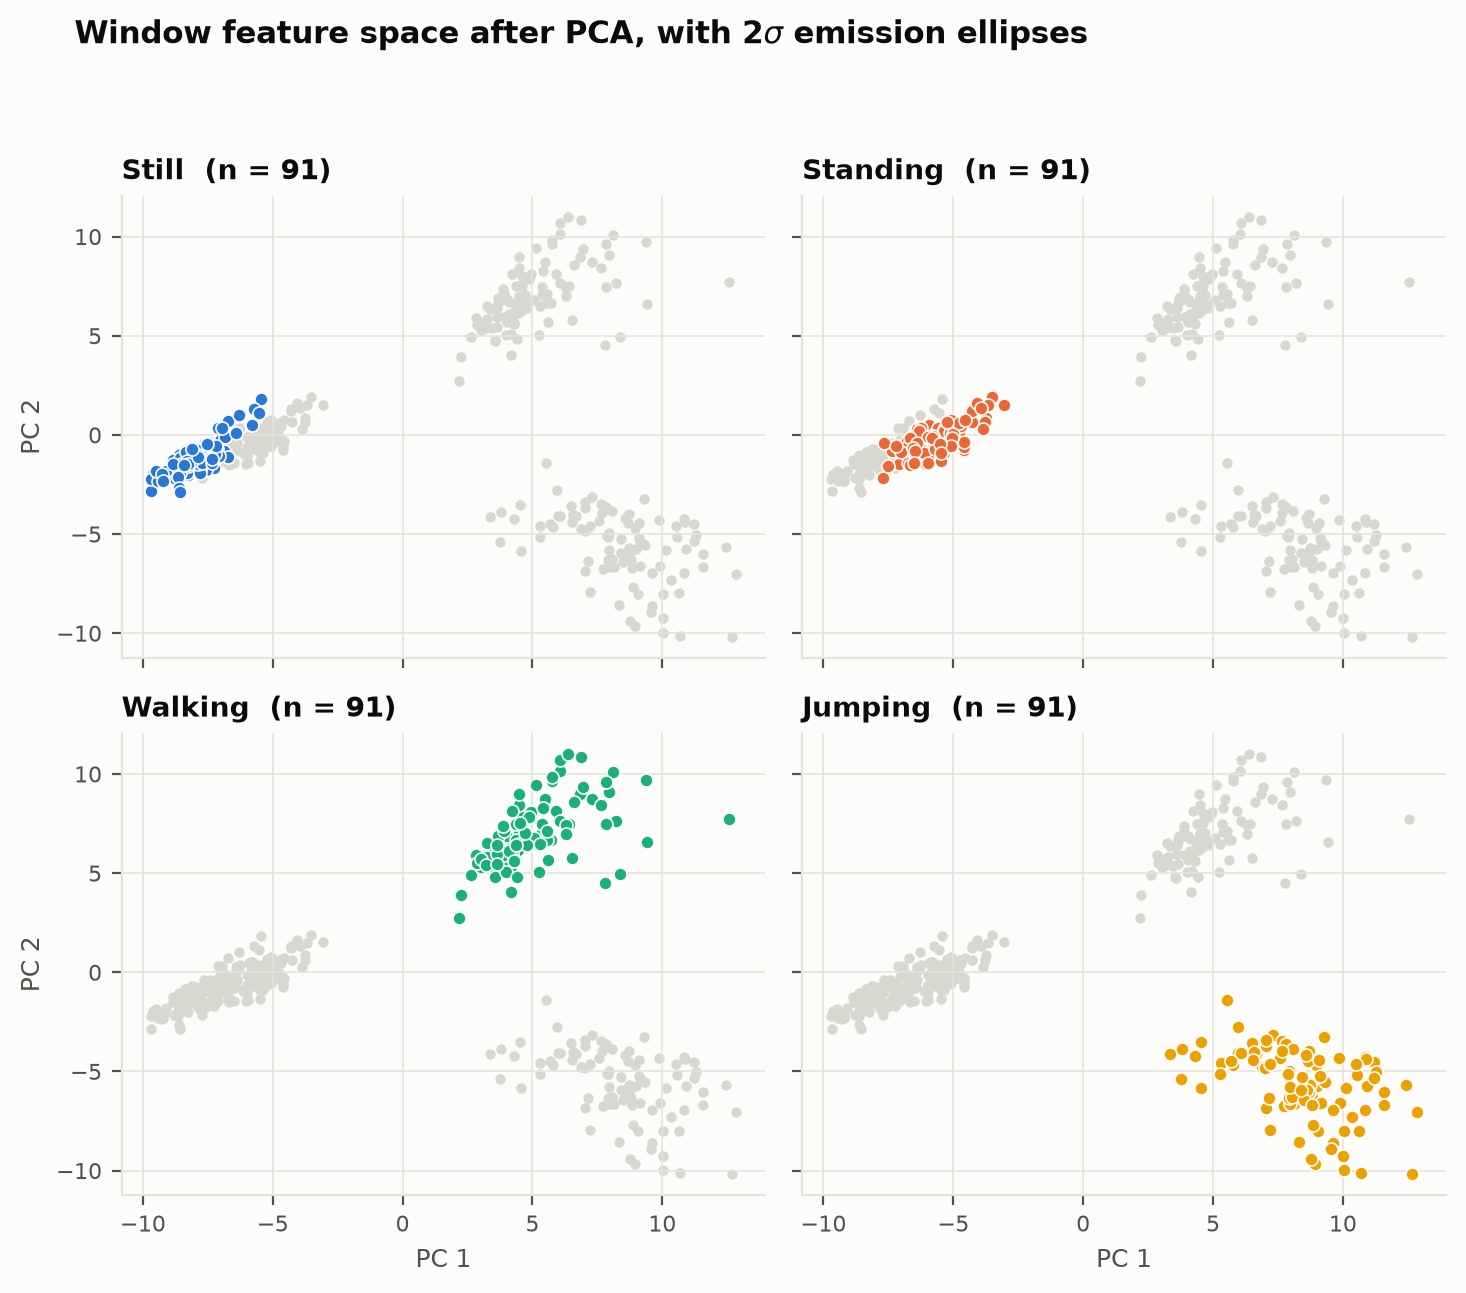

In [9]:
viz.plot_feature_space(Z_train, train.state.to_numpy())
display(Image(filename=str(viz.FIGURES / "06_feature_space.png")))

---
## 3. HMM setup and implementation

### 3.1 Model components

| Element | This project |
|---|---|
| **Hidden states Z** | 4 - Still, Standing, Walking, Jumping |
| **Observations X** | 4-dimensional PCA feature vector per 2 s window |
| **Transitions A** | 4x4 row-stochastic, estimated from the circuit recordings |
| **Emissions B** | multivariate Gaussian per state, **diagonal** covariance |
| **Initial pi** | 4-vector over the first window of each sequence |

Diagonal rather than full covariance: a full 4x4 covariance per state would be 10
parameters per state instead of 4, and with 91 windows per class the estimate would be
poorly conditioned. The cost is an assumption that the PCA components are conditionally
independent given the state - reasonable, since PCA components are uncorrelated
globally by construction.

### 3.2 Implementation

`src/hmm.py` implements the model from scratch in numpy. **Everything runs in log
space** using `scipy.special.logsumexp`: a 100-step product of small Gaussian densities
underflows float64 almost immediately, and a linear-space implementation silently
returns zero.

| Routine | Role |
|---|---|
| `log_emission` | log p(x_t \| z_t = k), the diagonal Gaussian written out explicitly |
| `forward` | log alpha and the sequence log-likelihood |
| `backward` | log beta |
| `posteriors` | gamma and xi, the per-step and pairwise state posteriors |
| `viterbi` | the MAP state path - **this produces the predicted labels** |
| `map_decode` | per-window posterior decode, for comparison |
| `fit_supervised` | closed-form MLE from labelled windows |
| `fit_baum_welch` | unsupervised EM |
| `align_states` | Hungarian matching of learned states onto activity names |

### 3.3 Which algorithms, and how they connect to the evaluation metrics

- **Forward** computes P(X | lambda). It is a *model-level* score, used to compare the
  supervised fit against the Baum-Welch fit. It does not produce per-window labels, so
  it cannot produce sensitivity or specificity.
- **Baum-Welch** (forward-backward inside EM) is the *learning* algorithm when labels
  are unavailable. Here labels exist, so closed-form MLE replaces it for the reported
  model; Baum-Welch is run separately to show the activities are recoverable without
  supervision at all.
- **Viterbi** is the *decoding* algorithm and the one that matters for the metrics. Its
  output is the predicted state per window, which is exactly what the confusion matrix
  is built from, and therefore what sensitivity, specificity and accuracy are computed
  from. Because it maximises the probability of the **whole path** rather than each
  window independently, it enforces temporal consistency and suppresses isolated
  single-window flips that a frame-by-frame classifier would emit.
- **Posterior (MAP) decoding** maximises expected per-window accuracy but can return a
  path the transition matrix assigns zero probability. Both are reported in section 4.

### 3.4 Correctness

Rather than trusting the implementation, nineteen properties are checked against
synthetic data where the answer is known independently. Two are decisive: the forward
algorithm must equal brute-force enumeration over **all** state paths, and Viterbi must
return the exact brute-force argmax path.

In [10]:
import subprocess
result = subprocess.run([sys.executable, "check_hmm.py"],
                        cwd=str(Path.cwd().parent / "src"),
                        capture_output=True, text=True)
print(result.stdout)
assert result.returncode == 0, "HMM correctness checks failed"

[PASS] emission density integrates to 1                           per-state mass [1. 1. 1.]
[PASS] forward and backward give the same log-likelihood          -198.9781104873 vs -198.9781104873
[PASS] gamma sums to 1 at every step                            
[PASS] xi sums to 1 at every step                               
[PASS] xi marginalises to gamma                                 
[PASS] forward equals brute-force path enumeration                -18.2856264388 vs -18.2856264388 over 729 paths
[PASS] Viterbi equals brute-force best path                       [0, 1, 1, 1, 0, 0, 0] vs [0, 1, 1, 1, 0, 0, 0]
[PASS] Viterbi path probability <= total likelihood             
[PASS] Baum-Welch log-likelihood is non-decreasing                7 iters, min step +9.38e-05, -5,053.9 -> -4,920.7
[PASS] Baum-Welch log-likelihood beats its own starting point     -5,053.9 -> -4,920.7
[PASS] Baum-Welch recovers 3 distinct states                      states used [0, 1, 2]
[PASS] Baum-Welch recovers th

### 3.5 Estimating the transition matrix

The 52 isolated clips each contain **one** activity, so they hold **zero** observed
transitions. An `A` estimated from them is the smoothing prior and nothing else - every
off-diagonal entry identical, carrying no information about behaviour. The two
continuous **circuit** recordings are the only real source of transitions.

`A` is counted at the **segment** level rather than from per-window labels. A segment of
an activity lasting D seconds contributes (D / hop - 1) self-transitions and exactly one
transition into the next activity, so only the *order* of activities and their *dwell
times* are used. Both survive the ~2 s reaction error in the hand-placed annotation
taps; per-window counting would inherit that error precisely at the boundaries, which
is where it does the most damage.

Smoothing is **0.1, not a full Laplace +1**. Every transition must stay strictly
positive or Viterbi can never cross that edge however strongly the emissions argue for
it - but the rows hold only 23 - 84 counts, and +1 per cell distorts the dwell times
encoded in the diagonal by up to a factor of two.

In [11]:
A, counts = estimate_A(segments, hop_s=HOP_SECONDS)
pi = estimate_pi(segments)

print("window-level transition counts (from the circuits)\n")
print(as_frame(counts).astype(int).to_string())
print(f"\ntransition matrix A  (smoothing = {TRANSITION_SMOOTHING})\n")
print(as_frame(A).round(4).to_string())
print(f"\nrow sums {A.sum(1).round(10)}   smallest entry {A.min():.6f}")
print("\ninitial distribution pi:",
      ", ".join(f"{a} {p:.3f}" for a, p in zip(ACTIVITIES, pi)))
print("\ndwell times: measured against what the diagonal of A implies\n")
print(dwell_summary(segments, hop_s=HOP_SECONDS).round(2).to_string(index=False))

window-level transition counts (from the circuits)

          Still  Standing  Walking  Jumping
Still        44         2        1        1
Standing      2        80        2        0
Walking       0         1       31        1
Jumping       0         2        0       21

transition matrix A  (smoothing = 0.1)

           Still  Standing  Walking  Jumping
Still     0.9112    0.0434   0.0227   0.0227
Standing  0.0249    0.9491   0.0249   0.0012
Walking   0.0030    0.0329   0.9311   0.0329
Jumping   0.0043    0.0897   0.0043   0.9017

row sums [1. 1. 1. 1.]   smallest entry 0.001185

initial distribution pi: Still 0.875, Standing 0.042, Walking 0.042, Jumping 0.042

dwell times: measured against what the diagonal of A implies

activity  segments  mean_dwell_s  min_dwell_s  max_dwell_s  self_transition  implied_mean_dwell_s
   Still         4         12.05         7.52        16.09             0.91                 11.26
Standing         5         16.91        10.80        23.76           

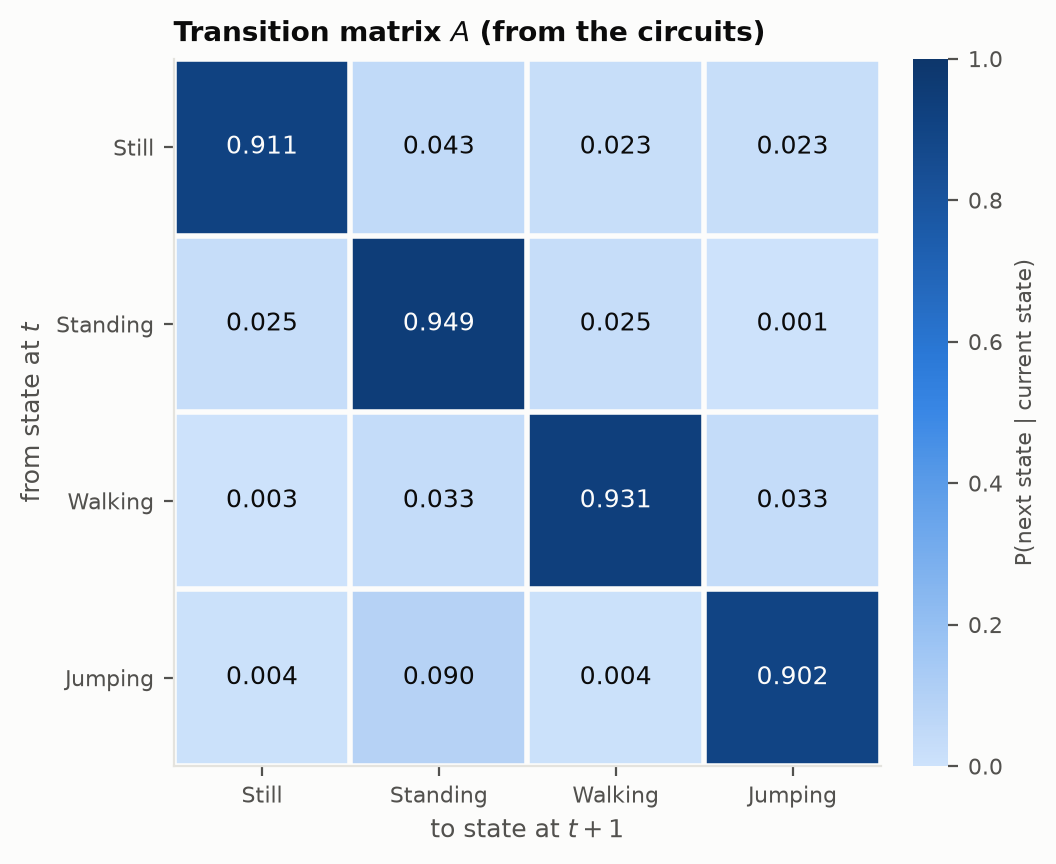

In [12]:
viz.plot_transition_heatmap(A, title="Transition matrix $A$ (from the circuits)")
display(Image(filename=str(viz.FIGURES / "03_transition_matrix.png")))

In [13]:
# Fit the emissions from the labelled isolated clips, then install the
# circuit-derived A and pi.
seqs_train, labels_train, _ = to_sequences(train, Z_train)
model = GaussianHMM(len(ACTIVITIES), N_COMPONENTS,
                    seed=RANDOM_SEED).fit_supervised(seqs_train, labels_train)
A_isolated = model.A.copy()          # keep the degenerate one for the ablation
model.set_params(pi, A, model.mu, model.var)

print(f"{len(seqs_train)} training sequences of {seqs_train[0].shape[0]} windows "
      f"x {seqs_train[0].shape[1]} dimensions")
print(f"train log-likelihood {model.log_likelihood(seqs_train):,.2f}\n")
print("emission means mu_k\n")
print(pd.DataFrame(model.mu, index=ACTIVITIES,
                   columns=[f"PC{i+1}" for i in range(N_COMPONENTS)]).round(3).to_string())
print("\nemission variances sigma^2_k\n")
print(pd.DataFrame(model.var, index=ACTIVITIES,
                   columns=[f"PC{i+1}" for i in range(N_COMPONENTS)]).round(3).to_string())

52 training sequences of 7 windows x 4 dimensions
train log-likelihood -2,360.24

emission means mu_k

            PC1    PC2    PC3    PC4
Still    -7.962 -1.160 -2.813  0.335
Standing -5.530 -0.197  3.134 -0.641
Walking   5.119  6.997 -0.133  0.254
Jumping   8.372 -5.640 -0.188  0.053

emission variances sigma^2_k

            PC1    PC2    PC3     PC4
Still     0.879  0.814  0.720   0.147
Standing  0.922  0.589  1.013   0.145
Walking   3.122  2.758  2.896  14.390
Jumping   4.166  3.220  0.702   1.145


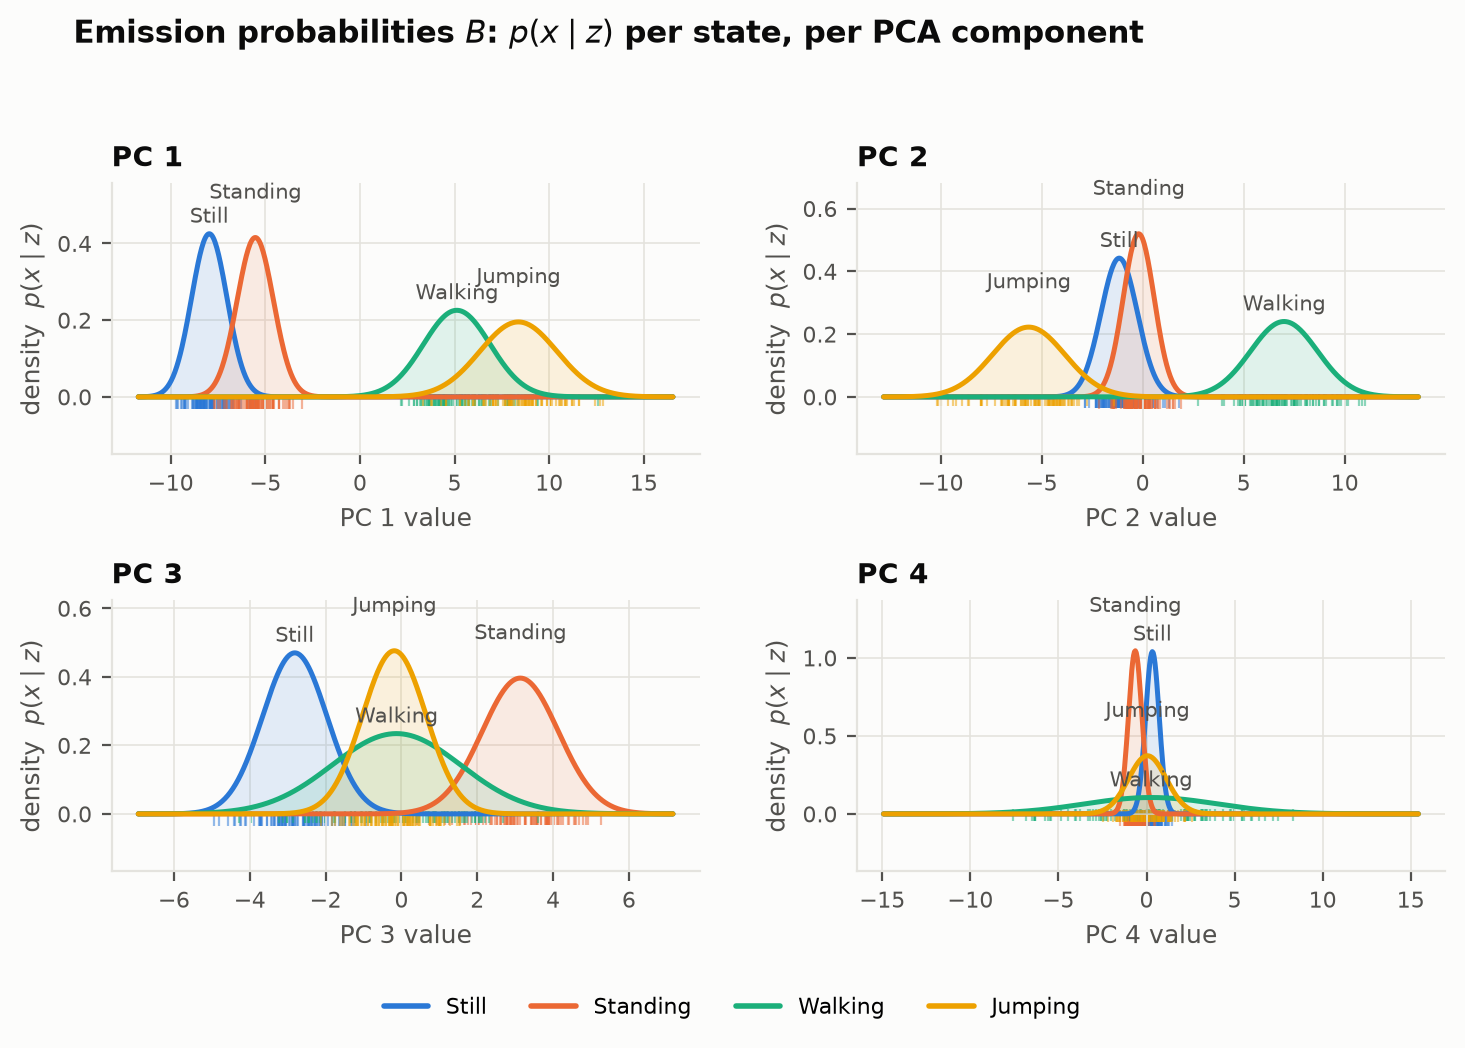

In [14]:
viz.plot_emissions(model.mu, model.var, Z=Z_train, y=train.state.to_numpy())
display(Image(filename=str(viz.FIGURES / "09_emissions.png")))

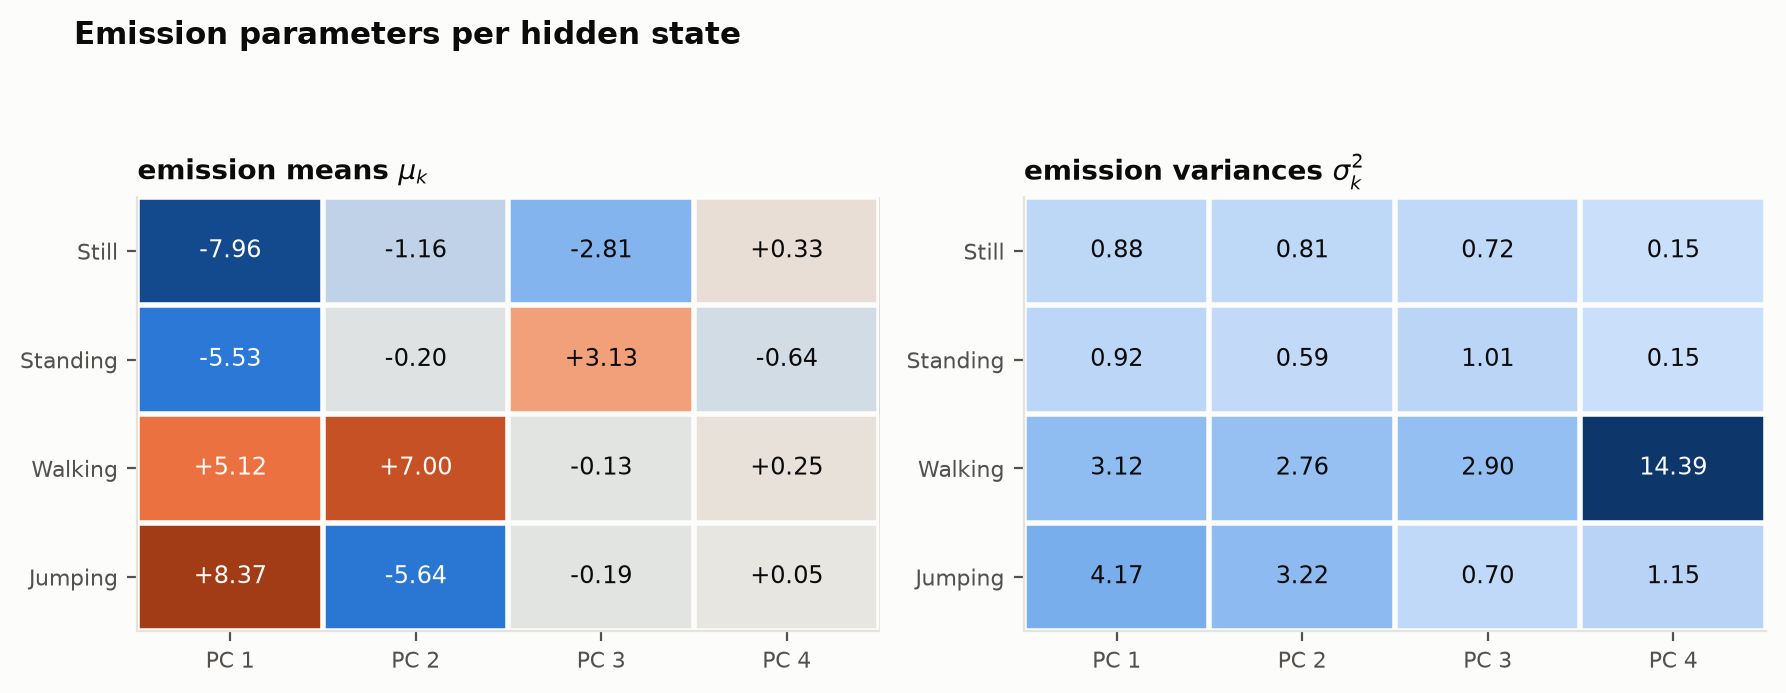

In [15]:
viz.plot_emission_parameters(model.mu, model.var)
display(Image(filename=str(viz.FIGURES / "09b_emission_parameters.png")))

### 3.6 Baum-Welch

The same model, fitted with the labels **withheld**, to test whether the four
activities are recoverable without supervision.

EM stops on the **relative** improvement in total log-likelihood,
(L_t - L_{t-1}) / |L_{t-1}| < 1e-6. Relative rather than absolute because the total
log-likelihood scales with the number and length of sequences, so an absolute threshold
would stop too early or too late depending on the dataset size. EM is provably monotone,
so the loop also raises if the likelihood ever decreases - that would be a bug, not a
search needing a restart.

Because EM has no idea which cluster we chose to call "Walking", the learned state
numbering is arbitrary and is resolved against the true labels with the Hungarian
algorithm before any metric is computed.

In [16]:
bw = GaussianHMM(len(ACTIVITIES), N_COMPONENTS, seed=RANDOM_SEED)
bw.fit_baum_welch(seqs_train, n_iter=200, tol=1e-6, init="kmeans", verbose=True)

mapping = align_states(np.concatenate([bw.viterbi(X) for X in seqs_train]),
                       np.concatenate(labels_train), len(ACTIVITIES))
print(f"\nconverged: {bw.converged_} after {bw.n_iter_} iterations")
print(f"log-likelihood {bw.loglik_history_[0]:,.2f} -> {bw.loglik_history_[-1]:,.2f}")
print(f"monotone non-decreasing: {bool((np.diff(bw.loglik_history_) >= -1e-9).all())}")
print(f"Hungarian mapping (learned -> true): {mapping}")

bw_pred = remap(np.concatenate([bw.viterbi(X) for X in seqs_train]), mapping)
gold_train = np.concatenate(labels_train)
print(f"\nagreement with the true labels after alignment: "
      f"{(bw_pred == gold_train).mean():.4f}")
print(f"\nsupervised  log-likelihood {model.log_likelihood(seqs_train):,.2f}")
print(f"Baum-Welch  log-likelihood {bw.log_likelihood(seqs_train):,.2f}")

  iter   1  loglik -2,314.557
  iter   2  loglik -2,281.685  rel. improvement 1.42e-02
  iter   3  loglik -2,281.685  rel. improvement 1.42e-07



converged: True after 3 iterations
log-likelihood -2,314.56 -> -2,281.68
monotone non-decreasing: True
Hungarian mapping (learned -> true): {0: 3, 1: 0, 2: 2, 3: 1}

agreement with the true labels after alignment: 1.0000

supervised  log-likelihood -2,360.24
Baum-Welch  log-likelihood -2,281.68


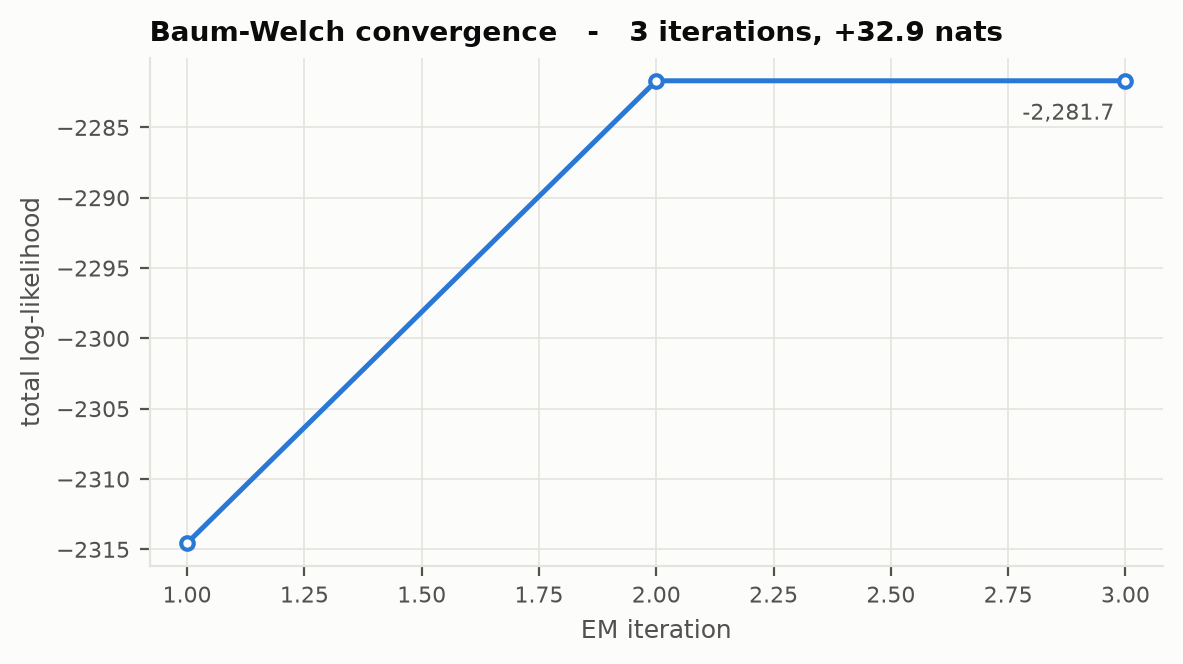

In [17]:
viz.plot_loglik_curve(bw.loglik_history_)
display(Image(filename=str(viz.FIGURES / "07_em_convergence.png")))

---
## 4. Results and interpretation

Three test conditions, reported separately because they answer different questions.

### 4.1 Held-out recordings from the training session

Split **by recording, never by window**. Windows overlap by 50%, so two windows from one
clip share half their samples; splitting by window would put overlapping halves on both
sides and leak badly. This answers the easy question: does the model generalise past
the specific clips it was fitted on?

In [18]:
tr_recs, te_recs = split_recordings(train, n_test_per_activity=3, seed=RANDOM_SEED)
tr, te = subset(train, tr_recs), subset(train, te_recs)
pre_split = Preprocessor(n_components=N_COMPONENTS).fit(tr)

s_tr, l_tr, _ = to_sequences(tr, pre_split.transform(tr))
s_te, l_te, _ = to_sequences(te, pre_split.transform(te))

split_model = GaussianHMM(len(ACTIVITIES), N_COMPONENTS,
                          seed=RANDOM_SEED).fit_supervised(s_tr, l_tr)
split_model.set_params(pi, A, split_model.mu, split_model.var)

pred = np.concatenate([split_model.viterbi(X) for X in s_te])
gold = np.concatenate(l_te)
print(f"held out {len(te_recs)} recordings: {', '.join(te_recs)}\n")
print(format_report(per_state_report(gold, pred, ACTIVITIES)).to_string(index=False))
print("\n", {k: round(v, 4) if isinstance(v, float) else v
             for k, v in overall(gold, pred).items()})

held out 12 recordings: Jumping_01, Jumping_09, Jumping_10, Standing_02, Standing_10, Standing_13, Still_06, Still_10, Still_12, Walking_02, Walking_07, Walking_09

State (Activity)  Number of Samples  Sensitivity  Specificity  Overall Accuracy
           Still                 21          1.0          1.0               1.0
        Standing                 21          1.0          1.0               1.0
         Walking                 21          1.0          1.0               1.0
         Jumping                 21          1.0          1.0               1.0

 {'n_windows': 84, 'accuracy': 1.0, 'macro_f1': 1.0, 'macro_sensitivity': 1.0, 'macro_specificity': 1.0}


### 4.2 Unseen data - a different session, room and phone placement

This is the evaluation the brief asks for. The unseen data was obtained as a
**separate recording session on a later day**, in a **different room**, with the phone
carried in a **trouser pocket** rather than held in the hand. Three files per activity,
twelve in total, processed through exactly the same pipeline - the preprocessor,
scaler and PCA basis were fitted on the training session alone and applied unchanged,
so nothing about this session influenced the model.

In [19]:
seqs_un, labels_un, names_un = to_sequences(unseen_tbl, Z_unseen)
pred_un = np.concatenate([model.viterbi(X) for X in seqs_un])
gold_un = np.concatenate(labels_un)

report_un = per_state_report(gold_un, pred_un, ACTIVITIES)
print("EVALUATION ON UNSEEN DATA\n")
print(format_report(report_un).to_string(index=False))
stats_un = overall(gold_un, pred_un)
print(f"\noverall accuracy {stats_un['accuracy']:.4f}   "
      f"macro F1 {stats_un['macro_f1']:.4f}   "
      f"({stats_un['n_windows']} windows)")

EVALUATION ON UNSEEN DATA

State (Activity)  Number of Samples  Sensitivity  Specificity  Overall Accuracy
           Still                 21       0.1429       1.0000            0.7857
        Standing                 21       0.4762       0.7302            0.6667
         Walking                 21       1.0000       0.8095            0.8571
         Jumping                 21       1.0000       1.0000            1.0000

overall accuracy 0.6548   macro F1 0.6111   (84 windows)


confusion matrix, unseen data (rows = true, columns = predicted)

          Still  Standing  Walking  Jumping
Still         3        17        1        0
Standing      0        10       11        0
Walking       0         0       21        0
Jumping       0         0        0       21


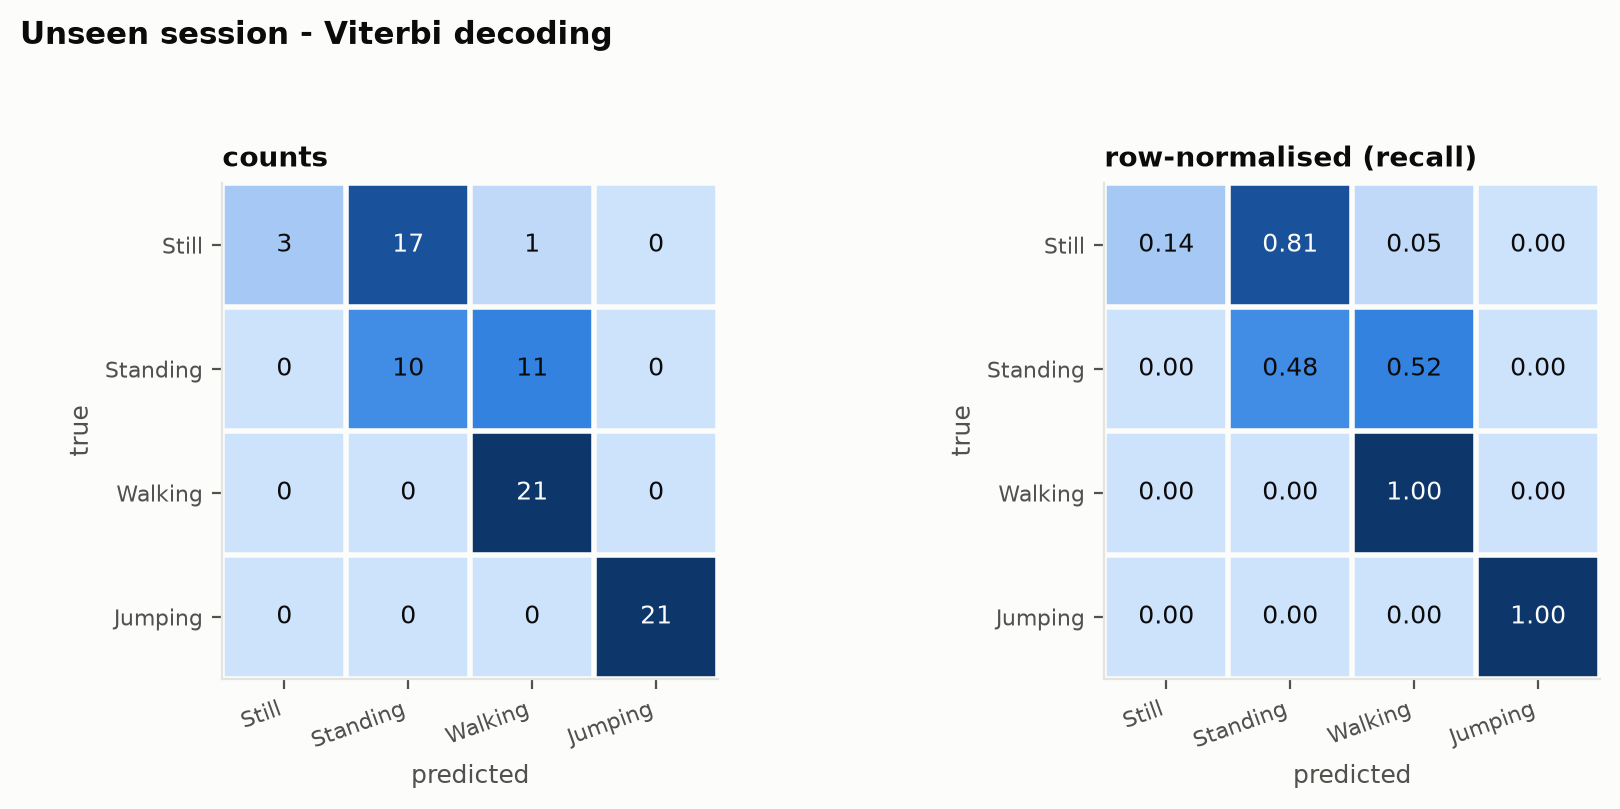

In [20]:
cm_un = confusion(gold_un, pred_un, len(ACTIVITIES))
print("confusion matrix, unseen data (rows = true, columns = predicted)\n")
print(as_frame(cm_un).astype(int).to_string())
viz.plot_confusion(cm_un, title="Unseen session - Viterbi decoding")
display(Image(filename=str(viz.FIGURES / "04_confusion.png")))

In [21]:
print("per recording\n")
for n, X, yy in zip(names_un, seqs_un, labels_un):
    p = model.viterbi(X)
    print(f"  {n:13s} true={ACTIVITIES[yy[0]]:9s} acc={(p == yy).mean():.2f}   "
          f"{' '.join(ACTIVITIES[q][:4] for q in p)}")

# Viterbi against per-window posterior decoding
map_pred = np.concatenate([model.map_decode(X) for X in seqs_un])
print(f"\nViterbi accuracy {(pred_un == gold_un).mean():.4f}")
print(f"MAP     accuracy {(map_pred == gold_un).mean():.4f}")
print(f"the two paths differ on {(map_pred != pred_un).sum()} of {len(pred_un)} windows")

per recording

  Jumping_U1    true=Jumping   acc=1.00   Jump Jump Jump Jump Jump Jump Jump
  Jumping_U2    true=Jumping   acc=1.00   Jump Jump Jump Jump Jump Jump Jump
  Jumping_U3    true=Jumping   acc=1.00   Jump Jump Jump Jump Jump Jump Jump
  Standing_U1   true=Standing  acc=0.00   Walk Walk Walk Walk Walk Walk Walk
  Standing_U2   true=Standing  acc=0.86   Stan Stan Stan Stan Stan Stan Walk
  Standing_U3   true=Standing  acc=0.57   Stan Stan Walk Walk Stan Stan Walk
  Still_U1      true=Still     acc=0.00   Stan Stan Stan Stan Stan Stan Stan
  Still_U2      true=Still     acc=0.00   Stan Stan Stan Stan Stan Stan Stan
  Still_U3      true=Still     acc=0.43   Walk Stan Stil Stil Stil Stan Stan
  Walking_U1    true=Walking   acc=1.00   Walk Walk Walk Walk Walk Walk Walk
  Walking_U2    true=Walking   acc=1.00   Walk Walk Walk Walk Walk Walk Walk
  Walking_U3    true=Walking   acc=1.00   Walk Walk Walk Walk Walk Walk Walk

Viterbi accuracy 0.6548
MAP     accuracy 0.6548
the two path

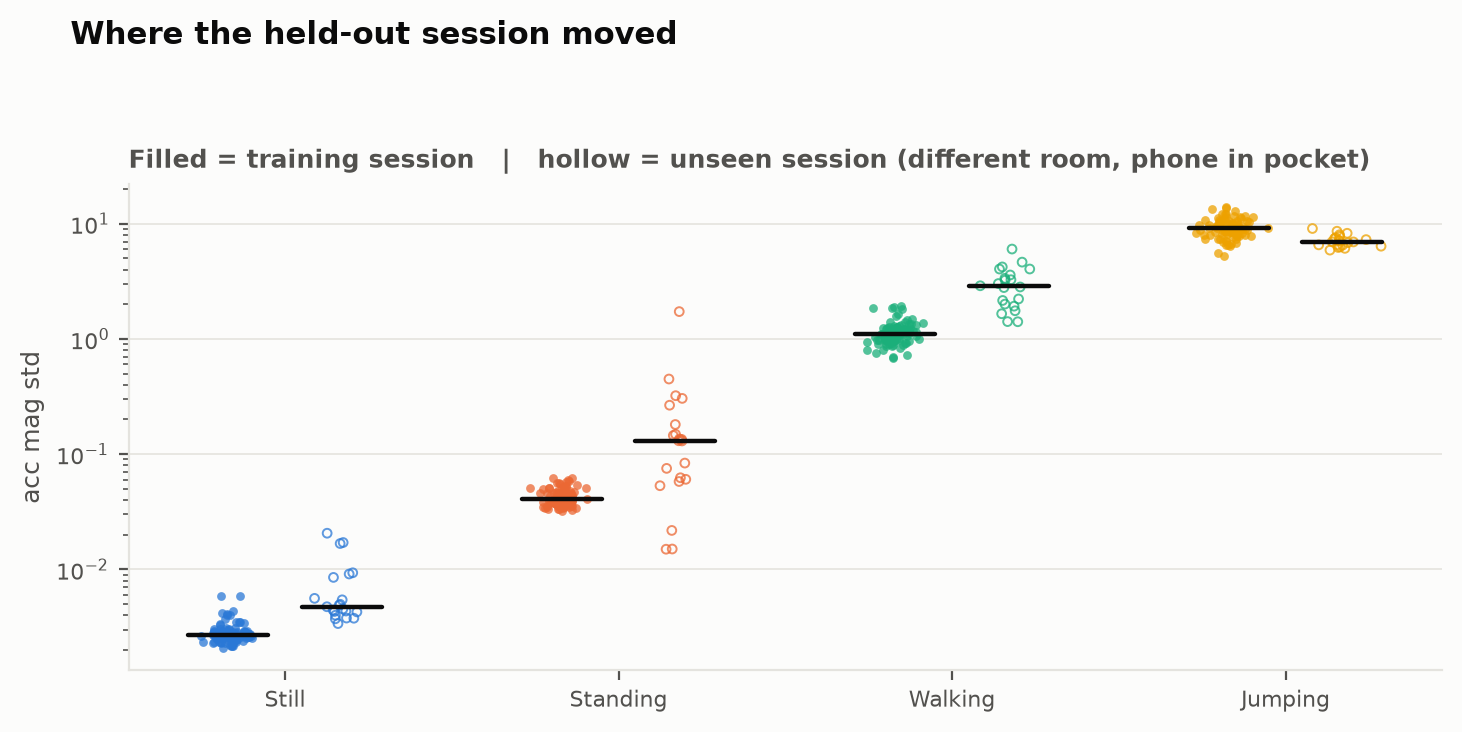

In [22]:
viz.plot_separability(train, unseen_tbl)
display(Image(filename=str(viz.FIGURES / "08_separability.png")))

### 4.3 Decoding the continuous circuits

The circuits are the only recordings containing real transitions, so they are the only
place a decoded *sequence* can be shown against ground truth. Their boundaries come
from hand-placed annotation taps carrying ~2 s of reaction error, so windows within
3 s of a boundary are shaded as a guard band and metrics are reported both with and
without them.

In [23]:
from features import build_continuous_feature_table

circuits = build_continuous_feature_table(circuit_samples)
seqs_ci, labels_ci, names_ci = to_sequences(circuits, pre.transform(circuits))

pred_ci = np.concatenate([model.viterbi(X) for X in seqs_ci])
gold_ci = np.concatenate(labels_ci)
order = circuits.sort_values(["recording", "window_index"]).index.to_numpy()
guard = ~circuits.loc[order, "near_boundary"].to_numpy(bool)

print("circuits, all windows")
print(f"  accuracy {(pred_ci == gold_ci).mean():.4f}  ({len(gold_ci)} windows)")
print("circuits, outside the annotation guard band")
print(f"  accuracy {(pred_ci[guard] == gold_ci[guard]).mean():.4f}  "
      f"({guard.sum()} windows)\n")
print(format_report(per_state_report(gold_ci[guard], pred_ci[guard],
                                     ACTIVITIES)).to_string(index=False))

circuits, all windows
  accuracy 0.6237  (186 windows)
circuits, outside the annotation guard band
  accuracy 0.6778  (90 windows)

State (Activity)  Number of Samples  Sensitivity  Specificity  Overall Accuracy
           Still                 23       0.6957       1.0000            0.9222
        Standing                 49       0.5510       1.0000            0.7556
         Walking                 12       1.0000       0.7949            0.8222
         Jumping                  6       1.0000       0.8452            0.8556


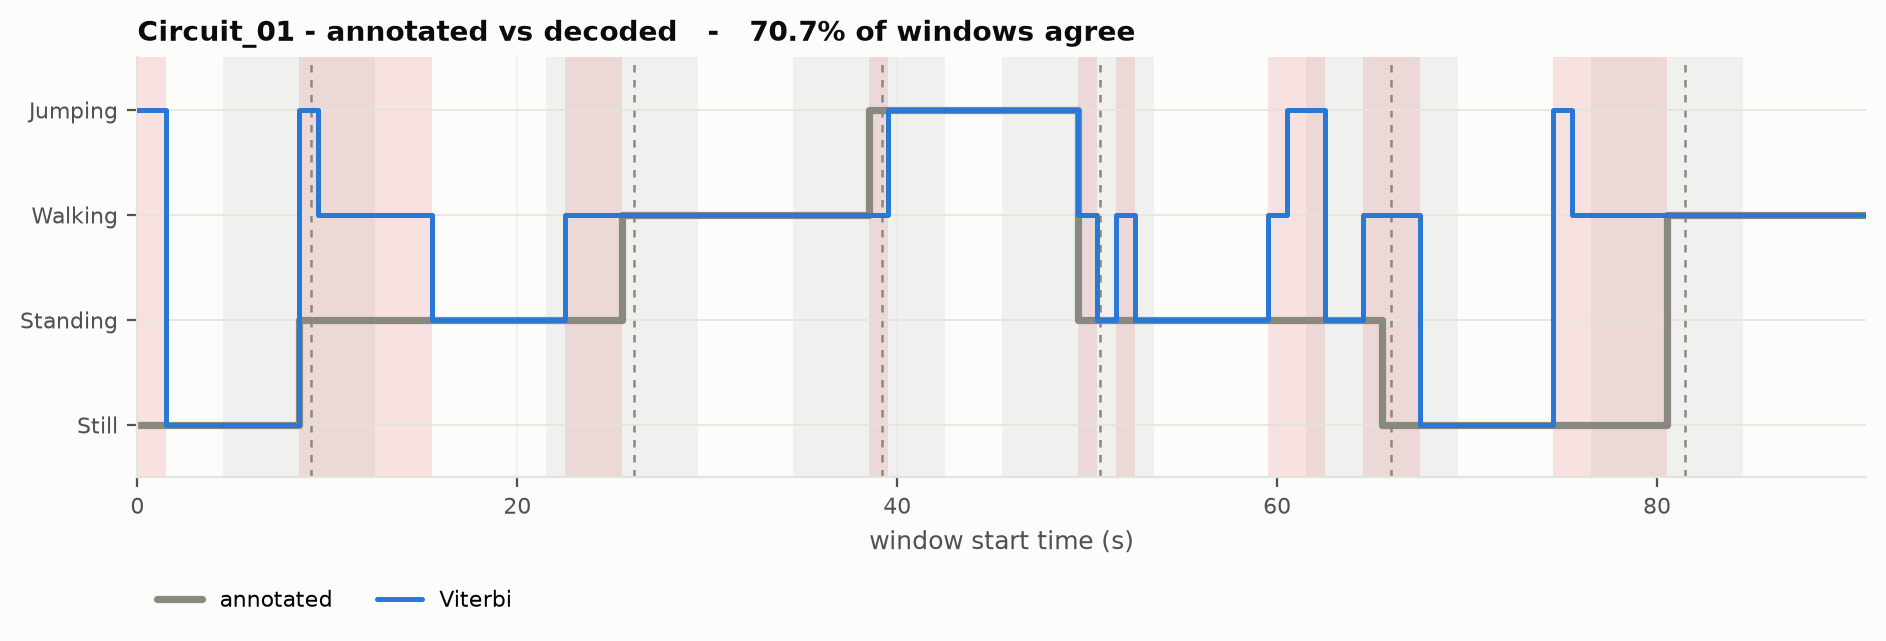

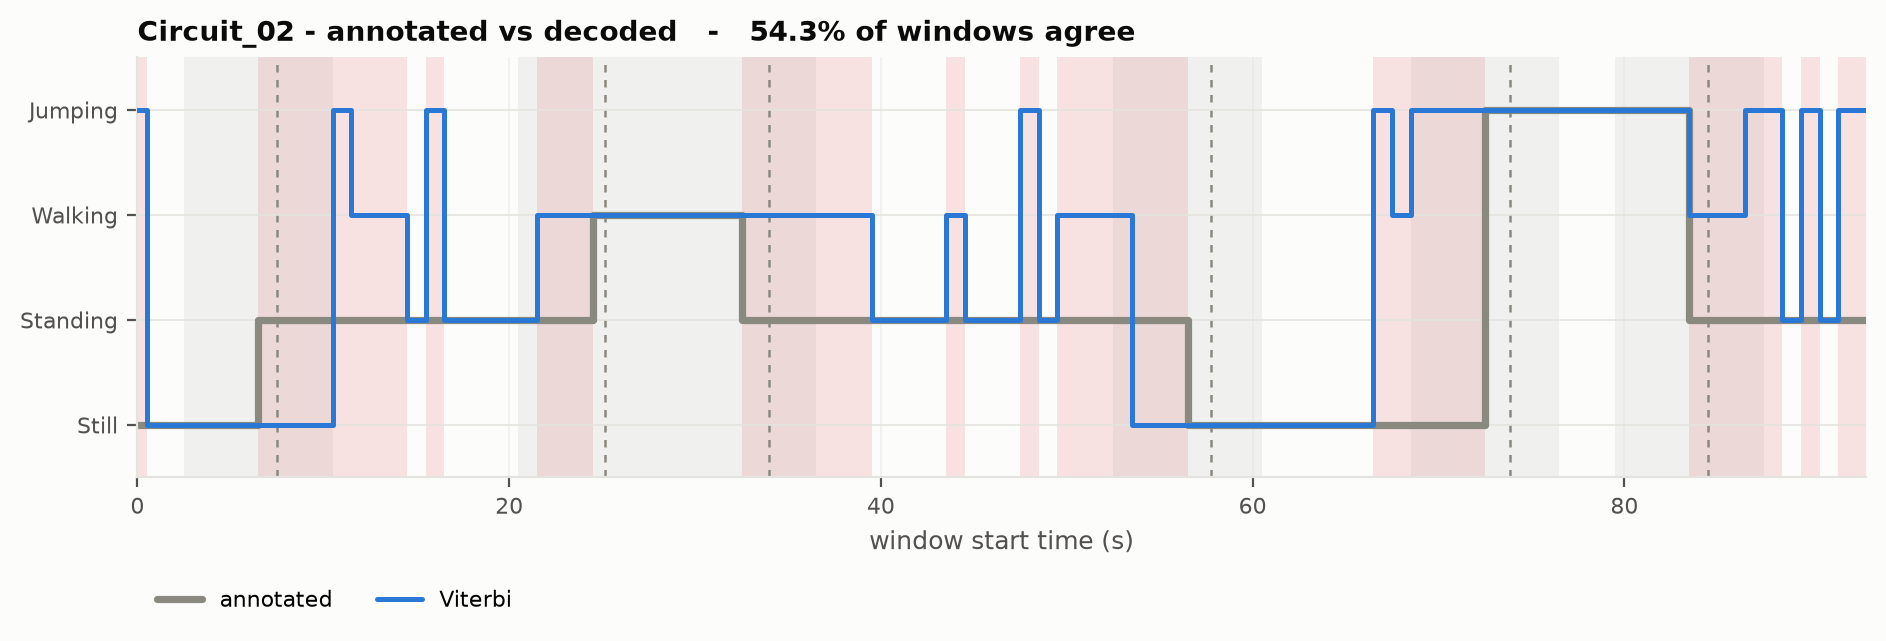

In [24]:
for name, X, yy in zip(names_ci, seqs_ci, labels_ci):
    grp = circuits[circuits.recording == name].sort_values("window_index")
    bounds = segments.loc[segments.recording == name, "start_s"].to_numpy()[1:]
    path = viz.plot_decoded_sequence(
        yy, model.viterbi(X), t=grp.t_start.to_numpy(),
        guard=grp.near_boundary.to_numpy(bool), boundaries=list(bounds),
        path=viz.FIGURES / f"05_decoded_{name.lower()}.png",
        title=f"{name} - annotated vs decoded")
    display(Image(filename=str(path)))

### 4.4 Does the transition matrix actually matter?

An ablation: replace the circuit-derived `A` with the degenerate one estimated from the
isolated clips, where every off-diagonal entry is identical because no transition was
ever observed.

In [25]:
print("A from the isolated clips (no transitions exist in them)\n")
print(as_frame(A_isolated).round(4).to_string())

degenerate = GaussianHMM(len(ACTIVITIES), N_COMPONENTS, seed=RANDOM_SEED)
degenerate.set_params(np.full(len(ACTIVITIES), 1 / len(ACTIVITIES)),
                      A_isolated, model.mu, model.var)
deg_pred = np.concatenate([degenerate.viterbi(X) for X in seqs_ci])
print(f"\ncircuits, circuit-derived A : {(pred_ci == gold_ci).mean():.4f}")
print(f"circuits, degenerate A     : {(deg_pred == gold_ci).mean():.4f}")
print(f"paths differ on {(deg_pred != pred_ci).sum()} of {len(pred_ci)} windows")

A from the isolated clips (no transitions exist in them)

           Still  Standing  Walking  Jumping
Still     0.9634    0.0122   0.0122   0.0122
Standing  0.0122    0.9634   0.0122   0.0122
Walking   0.0122    0.0122   0.9634   0.0122
Jumping   0.0122    0.0122   0.0122   0.9634

circuits, circuit-derived A : 0.6237
circuits, degenerate A     : 0.6237
paths differ on 1 of 186 windows


In [26]:
rows = [
    ("held-out recordings (same session)", gold, pred),
    ("unseen session (different room, pocket)", gold_un, pred_un),
    ("circuits, all windows", gold_ci, pred_ci),
    ("circuits, outside guard band", gold_ci[guard], pred_ci[guard]),
    ("Baum-Welch, unsupervised (train)", gold_train, bw_pred),
]
summary_tbl = pd.DataFrame([
    {"condition": name, **{k: v for k, v in overall(g, p).items()}}
    for name, g, p in rows])
print("SUMMARY\n")
print(summary_tbl.round(4).to_string(index=False))

SUMMARY

                              condition  n_windows  accuracy  macro_f1  macro_sensitivity  macro_specificity
     held-out recordings (same session)         84    1.0000    1.0000             1.0000             1.0000
unseen session (different room, pocket)         84    0.6548    0.6111             0.6548             0.8849
                  circuits, all windows        186    0.6237    0.6346             0.7453             0.8871
           circuits, outside guard band         90    0.6778    0.6528             0.8117             0.9100
       Baum-Welch, unsupervised (train)        364    1.0000    1.0000             1.0000             1.0000


---
## 5. Discussion and conclusion

### Which activities were easiest and hardest

**Jumping is trivially separable** and stays at sensitivity 1.000 even on unseen data in
a different placement. It is the only activity with a distinctive *frequency* signature
(~3.6 Hz) as well as a large amplitude, and frequency ratios survive a change in how the
phone is carried in a way that raw amplitude does not.

**Walking** is also robust (sensitivity 1.000), for the same reason: a ~1 Hz cadence is a
shape, not a scale.

**Still and Standing are the hard pair**, and they fail in a specific, explainable way.
On same-session data they separate perfectly, because a phone on a table reads the
sensor noise floor (std 0.003 m/s^2) while a phone held in a hand picks up postural
sway (0.048) - a 16x gap. In the pocket that gap closes: body contact transmits micro-
movement to a phone that was previously decoupled from the body entirely.

### Why the unseen session degraded, precisely

The failure is **not random** - it is a one-step shift up the amplitude ladder. Still is
read as Standing, Standing is read as Walking, and nothing moves in the other direction.
Pocket placement inflated and widened every distribution: unseen Standing spans roughly
0.014 to 1.8 in `acc_mag` standard deviation, a range that covers where training Still,
training Standing *and* training Walking all live. The per-recording results track this
monotonically - the loudest Standing file is decoded 0/7 correct, the quietest 6/7.

This is a **covariate shift**, not a modelling error. The emission model is built on
features dominated by absolute amplitude, and absolute amplitude is exactly what
changed. In the clinical framing this is the serious failure: recording a patient who is
resting as "standing", or a phone left on a table as "the patient is upright", corrupts
precisely the adherence measure the system exists to produce.

### How the transition probabilities reflect realistic behaviour

The circuit-derived `A` is interpretable in a way the degenerate one is not:

- **Standing is the hub.** The largest off-diagonal entry in the whole matrix is
  Jumping -> Standing (0.090): you land and then stand.
- **Standing -> Jumping is the smallest (0.0012).** People do not leap from a standstill;
  they take a step first.
- **Walking -> Still is near zero (0.0030)**, which is physically right - "Still" means
  the phone has been set down, and you do not set a phone down mid-stride.
- **Self-transitions 0.90 - 0.95** reflect activities that persist for many seconds.

The implied mean dwell times (11.3, 19.6, 14.5, 10.2 s) track the measured ones (12.1,
16.9, 11.3, 11.1 s) closely. This only became true after reducing the smoothing from 1.0
to 0.1 - at +1 the implied dwells were roughly half the measured values, an artefact of
the prior rather than evidence against the geometric dwell assumption.

**But the ablation shows `A` barely affects decoding here.** With classes this separable
the emissions dominate completely, and Viterbi and MAP decoding agree on every window
of the unseen set. The transition structure is doing interpretive work, not predictive
work. That is an honest finding, not a disappointing one: it says the *measurement*
problem is the bottleneck, not the *sequence* problem - and it would change if the
activities were less separable or the sensor noisier.

### How sensor noise and sampling rate affected the model

50 Hz was comfortably sufficient: with Nyquist at 25 Hz and all activity energy below
~5 Hz, there is no aliasing, and the band-energy features above 10 Hz capture almost
nothing but sensor noise. The achieved rate drifted to 51.33 Hz with the two sensors on
independent clocks, which is why resampling onto a common grid was necessary rather
than cosmetic.

The real noise constraint is at the quiet end. Still sits at the accelerometer's noise
floor, so its "signal" is almost entirely sensor noise - which is why every statistic
undefined on a constant signal had to be explicitly guarded, and why Still's features
are the least stable across sessions.

Window length trades two things against each other. A 2 s window gives 0.5 Hz frequency
resolution, enough to separate walking from jumping, but it cannot localise a transition
better than about +/- 1 s - visible as lag at the boundaries in the decoded circuit plots.

### What would improve it

1. **Orientation- and scale-invariant features.** The single highest-value change. The
   unseen failure is entirely a change in signal *scale*, so per-recording
   normalisation, or features built from spectral *shape* and band-energy *ratios*
   rather than absolute amplitude, should recover much of the lost 35 points.
2. **Training data from multiple placements.** Hand, pocket, bag and armband in the
   training set would make the emission model placement-agnostic instead of
   placement-specific.
3. **More participants.** One participant means the model has learned one person's gait.
4. **A barometer channel**, which responds to the vertical displacement of jumping and
   is independent of the accelerometer's failure modes.
5. **Duration modelling (an HSMM).** A standard HMM gives each state a geometric dwell
   distribution, which is a poor description of real activities - the measured dwells
   cluster tightly around their means rather than decaying exponentially.
6. **More circuit recordings.** `A` rests on two recordings and 10 observed transitions,
   and pi on just two observations, which is why pi is weakly identified (0.875 for
   Still) even though it happens not to change the result.

### Conclusion

A four-state Gaussian HMM implemented from scratch separates the four activities
**perfectly on held-out recordings from the training session** (accuracy 1.000), and
Baum-Welch recovers the same four states **without labels at all**, which confirms the
activities form genuinely distinct clusters rather than classes the model was merely
told about.

On **genuinely unseen data** - a different day, room and phone placement - accuracy falls
to **0.655**, and the structure of that failure is the most informative result in the
project. Jumping and Walking, which have distinctive frequency signatures, survive
untouched at sensitivity 1.000. Still and Standing, which are distinguished only by
amplitude, collapse into their louder neighbours when the placement changes.

For the rehabilitation use case this is the right thing to have learned early: a system
deployed on amplitude features would report plausible-looking adherence data that was
systematically wrong in one direction, overstating patient activity. The fix is
identified and specific - scale-invariant features and multi-placement training data -
rather than simply "collect more data".

---
## References

Anguita, D., Ghio, A., Oneto, L., Parra, X., & Reyes-Ortiz, J. L. (2013). A public
domain dataset for human activity recognition using smartphones. *ESANN 2013*,
437-442.

Bao, L., & Intille, S. S. (2004). Activity recognition from user-annotated
acceleration data. *Pervasive Computing*, LNCS 3001, 1-17.

Baum, L. E., Petrie, T., Soules, G., & Weiss, N. (1970). A maximization technique
occurring in the statistical analysis of probabilistic functions of Markov chains.
*The Annals of Mathematical Statistics*, 41(1), 164-171.

Choi, L., Liu, Z., Matthews, C. E., & Buchowski, M. S. (2011). Validation of
accelerometer wear and nonwear time classification algorithm. *Medicine & Science
in Sports & Exercise*, 43(2), 357-364.

Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from
incomplete data via the EM algorithm. *Journal of the Royal Statistical Society:
Series B*, 39(1), 1-38.

Figo, D., Diniz, P. C., Ferreira, D. R., & Cardoso, J. M. P. (2010). Preprocessing
techniques for context recognition from accelerometer data. *Personal and
Ubiquitous Computing*, 14(7), 645-662.

Jolliffe, I. T. (2002). *Principal component analysis* (2nd ed.). Springer.

Kuhn, H. W. (1955). The Hungarian method for the assignment problem. *Naval
Research Logistics Quarterly*, 2(1-2), 83-97.

Prince, S. A., Adamo, K. B., Hamel, M. E., Hardt, J., Connor Gorber, S., &
Tremblay, M. (2008). A comparison of direct versus self-report measures for
assessing physical activity in adults: A systematic review. *International Journal
of Behavioral Nutrition and Physical Activity*, 5, 56.

Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications
in speech recognition. *Proceedings of the IEEE*, 77(2), 257-286.

Viterbi, A. J. (1967). Error bounds for convolutional codes and an asymptotically
optimum decoding algorithm. *IEEE Transactions on Information Theory*, 13(2),
260-269.

Yu, S.-Z. (2010). Hidden semi-Markov models. *Artificial Intelligence*, 174(2),
215-243.
